In [47]:
import numpy as np
import pandas as pd

Reading and inspecting the dataset

In [48]:
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

In [49]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [50]:
df.shape

(7043, 21)

##### so the shape is telling that the data has 7043 row and 21 columns which means 7043 customer and 21 feature

##### checking the columns /features

In [51]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


##### i have noticed that totalcharges column its type is object which not making sense as i expect numbers and any '' '' whitespaces changed to NAN

In [53]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype(str).str.strip(),
    errors='coerce')

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


 transforming the totalcharges column to numerical values , making sure to remove whitespaces , change any non converting value to NAN
' '' will be NANs

In [55]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df['TotalCharges'].isnull().sum() 

np.int64(11)

filling the NAN values with zeros instead because this make sense logically as these customers have no accmulated fees

In [14]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

checking the nulls after filling giving zeros

In [15]:
df['TotalCharges'].isnull().sum()

np.int64(0)

checking duplicates

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


### Outlier Detection and Treatment

The Modified Z-Score method identified 136 potential outliers in the "TotalCharges" column.

Further investigation revealed that these observations have:
- An average tenure of approximately 71.27 months
- An average MonthlyCharges of approximately 113.24
- An average TotalCharges of approximately 8,101.16

These findings suggest that the high TotalCharges values may be explained by long subscription periods and relatively high monthly charges rather than data-entry errors.

**Decision:** The identified observations were retained without removal or capping because they appear to represent plausible customer records. This decision is based on the available data and may be revisited if additional business information becomes available.

In [19]:
numerical_cols = df.select_dtypes(include=[np.number]).columns
outliers_summary = {}

for col in numerical_cols:
    data = df[col]
    median = data.median()
    mad = np.median(np.abs(data - median))
    if mad == 0:
        mad = 1e-4

    modified_z = 0.6745 * (data - median) / mad

    outliers_count = (np.abs(modified_z) > 3.5).sum()
    outliers_summary[col] = outliers_count

summary_df = pd.DataFrame(list(outliers_summary.items()), columns=['Col', 'outliers'])
print(summary_df)


              Col  outliers
0   SeniorCitizen      1142
1          tenure         0
2  MonthlyCharges         0
3    TotalCharges       136


In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

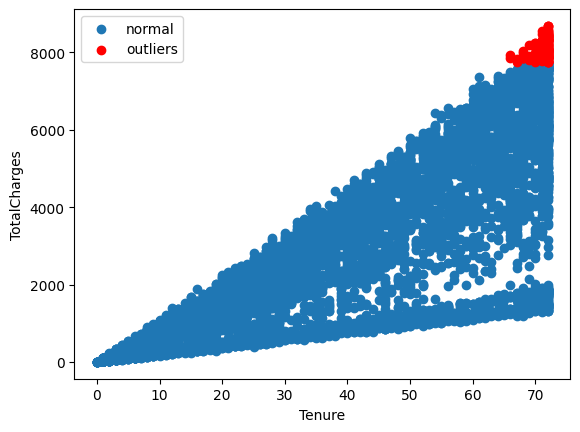

In [43]:
plt.scatter(normal['tenure'], normal['TotalCharges'], label='normal')

plt.scatter(outliers['tenure'], outliers['TotalCharges'], color='red', label='outliers')

plt.xlabel('Tenure')
plt.ylabel('TotalCharges')
plt.legend()
plt.show()

Found 136 outliers but from the business logic it make sense that these are customers that have high tenure may have high totalcharges because of the long time of subscribtions

tenure :(The number of months the customer has been with the company from the day they joined until the time the data was collected)

the red dots (outliers) are all clustered way up at the very top of the TotalCharges, and it clearly shows that they aren't random mistakes; these are the people with the highest Value for the company

**Customer and tenure distribution chart (histogram)**

shows that:

*    31.04% of customers have been with the company for 12 months or less
*    21.06% have maintained their subscriptions for at least 60 months.


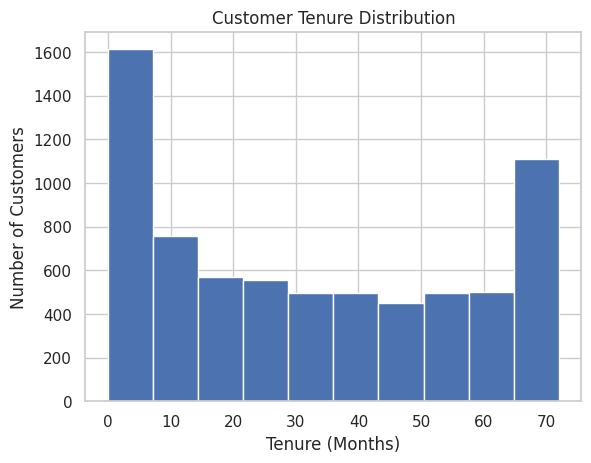

In [74]:
plt.hist(df['tenure'])

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

In [92]:
print("tenure(months of customer's subscription) <= 12 months:")
t= df['tenure']

print((t <= 12).sum())

print("tenure >= 60 months:")
print((t >= 60).sum())

tenure(months of customer's subscription) <= 12 months:
2186
tenure >= 60 months:
1483


In [66]:
print("Percentage of customers with tenure <= 12 months:")
print((df['tenure'] <= 12).sum() / len(df) * 100)

print("Percentage of customers with tenure >= 60 months:")
print((df['tenure'] >= 60).sum() / len(df) * 100)

Percentage of customers with tenure <= 12 months:
31.037909981541954
Percentage of customers with tenure >= 60 months:
21.05636802498935


In [93]:
print("Percentage <= 12 months:")
print((t <= 12).mean() * 100)

print("Percentage >= 60 months:")
print((t >= 60).mean() * 100)


Percentage <= 12 months:
31.037909981541954
Percentage >= 60 months:
21.05636802498935


**customer Churn distribution chart (countplot)**

the observation for the customer column with the target column shows that :
* 73.46% of customers did not churn (did not leave)
* 26.54% broke their subscriptions


This indicates a class imbalance in the target column, which should be considered when building model to be trained on this data  


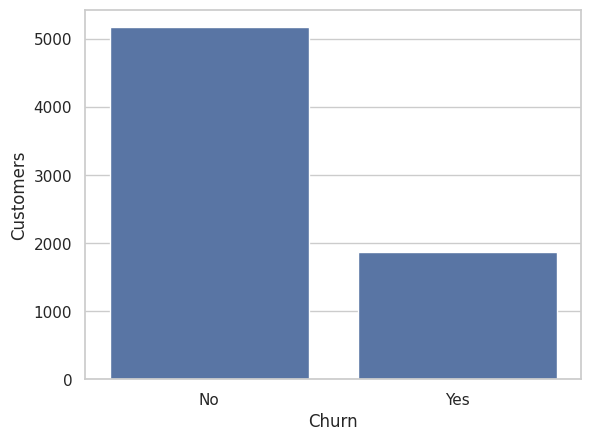

In [90]:
sns.countplot(x='Churn', data=df)
plt.ylabel('Customers')

plt.show()

In [88]:
x=df['Churn']
print(x.value_counts())
print(x.value_counts() / len(df) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64


**Monthly Charges vs Churn (boxplot)**

Customers who churned had higher monthly charges than those who stayed


*   The average monthly charge was 74.4 for churned customers
*    61.2 for non-churned customers

customers who canceled their subscription have a higher average monthly bill (median around 80)

 This suggests that higher monthly costs are one of the main drivers of churn

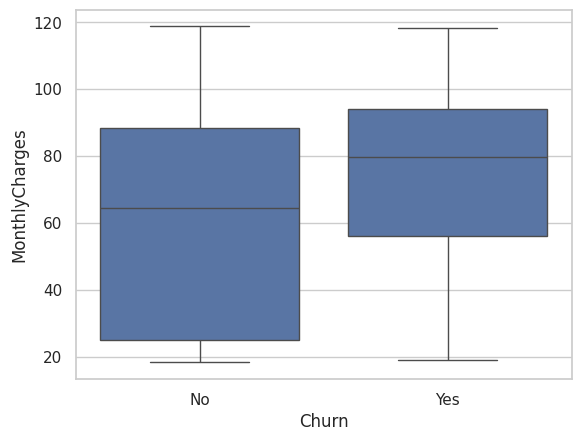

In [102]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.show()

In [131]:
df.groupby('Churn')['MonthlyCharges'].mean()

,MonthlyCharges
Churn,
No,61.265124
Yes,74.441332


**The churn Rate depending on contract Type (line plot)**



*   sharp downward in the churn rate as the contract duration increases

*   Month-to-month contracts record the highest churn rate, which drops for one-year contracts and reaches its lowest point for two-year contracts

*   Inverse relationship between contract length of time and churn


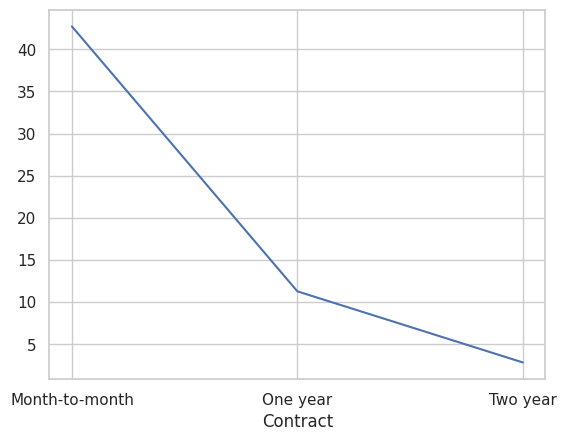

In [128]:
sns.lineplot(x=churn_rate.index, y=churn_rate.values)
plt.show()